We will learn how to use a Vogel-Fulcher-Tammann (VFT) model, described in <a href=https://www.sciencedirect.com/science/article/pii/S0012821X08002240> Giordano et al. (2008) </a> to compute viscosities of silicate magma. Read the paper for more information.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.insert(0,"/home/jovyan/shared/Libraries")
import VFTutils as VFT

The VFT equation that we will use is,

$$log_{10}\ \eta(T, H_2O) = a( H_2O) + \frac{b}{T-c(H_2O)}$$ 

where $T$ is the temperature, and $a,b,c$ are the model coeffecients. First, we will compute the model coefficients for our rock composition, and then compute $\eta$ for $T=1200 ^\circ$C. <b>(Always use input temperature in Celsius.)</b>

<p> The model coefficients capture the effects of 10 major and minor oxide components and the volatile components H$_2$O and F found in magmas. To use this VFT model, we first need to compute the coefficients from the major oxide wt $\%$ present in our magma of choice. Below is a an example of major oxide concentrations found in high-Si magma. </p>


In [2]:
whole_rock_oxides = {"SiO2": 62.40, 
                   "TiO2": 0.55, 
                   "Al2O3": 20.01,
                   "FeO": 0.03,
                   "MnO": 0.02,
                   "MgO": 3.22,
                   "CaO": 9.08,
                   "Na2O": 3.52,
                   "K2O": 0.93,
                   "P2O5": 0.12,
                   "H2O": 2.00}

The formulae needed for computing the model coefficients and viscosity are already defined in a library called VFTutils.py, which is located in the Libraries folder. We will use these pre-defined functions to get the model coeffiecients and viscosity next.

In [3]:
# Adding F2O
whole_rock_oxides["F2O"] = 0.50

# Model coeffiecients
norm_wt = VFT.get_norm_wt(whole_rock_oxides)
mol_percent = VFT.get_mol_percent(whole_rock_oxides, norm_wt)
# the norm_wt and mol_percent computations are correct if their total adds up to 100

a,b,c = VFT.get_model_coefficients(mol_percent)

#viscosity
T = 1200
visc = VFT.get_viscosity(T, a,b,c)   # returns log10(eta), not eta
print("The log viscosity is " + str(np.round(visc,3)), " Pas")

The log viscosity is 2.174  Pas


***

### <b><u> TASK 1: EFFECTS OF TEMPERATURE AND PRESSURE ON VISCOSITY</u></b>
#### <b> (1A) Finding whole rock and glass composition for a volcanic eruption </b>
Choose a volcano or a volcanic eruption that interests you or is relevant to your research. <b> Search the literature to find the major oxide compositions in weight percent for either the whole rock or the groundmass glass. In the cell below, include a link to the paper or report that you get this compositional info from. </b> 


An estimate of the magma temperature for your volcano/eruption choice is helpful, but not necessary. You can make assumptions as follows: 1200$^{\circ}$C for basalt; 1100$^{\circ}$C for basaltic andesite; 1000$^{\circ}$C for andesite; 900$^{\circ}$C for dacite; 800$^{\circ}$C for rhyolite)

In the cell below, create a python dictionary (as demonstrated earlier) contaning the major oxide composition for your whole rock or glass. <b> You need wt $\%$ values for all the 10 oxides and H$_2$O as shown above, because these are the elevn components (in addition to F) that go into computing the model coefficients. If you have other oxide information, you don't need to enter them here. If you are missing information for one of the oxides, that is okay, set it to zero. If you are missing information for more than one oxide, please search for another volcanic eruption in the literature.   

In [4]:
# enter your oxides composition for whole rock or ground mass glass below and uncomment
# whole_rock_oxides = {}

#### <b> (1B) Compute viscosity $\eta$ as a function of temperature and water content </b>
Modify the cells below to plot and compute viscosities for the following temperatures and water contents.

$$T=700 ^\circ, 800 ^\circ, 900 ^\circ, 1000 ^\circ, 1100 ^\circ, 1200 ^\circ\ C$$ . 
$$H_2O\ wt\% =4,3,2,1,0.1\ wt \%$$ . 

In [5]:
# viscosity computation
# input T and water variables
T = np.arange(700, 1300, 100)
h2o = np.array([4,3,2,1,0.1])

# etas is the array for storing the output
etas = np.zeros((len(h2o), len(T)), dtype=float)

# loop through h2o - for loop 1
for i in range(len(h2o)):

    # set h2o value in whole_rock_oxides as h2o[i]
    whole_rock_oxides["H2O"] = h2o[i]
    
    # compute model coefficients a, b, c
    # Model coeffiecients
    norm_wt = VFT.get_norm_wt(whole_rock_oxides)
    mol_percent = VFT.get_mol_percent(whole_rock_oxides, norm_wt)
    # the norm_wt and mol_percent computations are correct if their total adds up to 100

    a,b,c = VFT.get_model_coefficients(mol_percent)
    
    # loop through temperature and find viscosity etas[i, j] using T[j] - for loop 2
    for j in range(len(T)):
        etas[i,j] = VFT.get_viscosity(T[j], a,b,c)

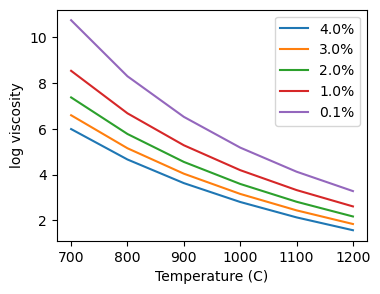

In [6]:
# plotting

fig, ax = plt.subplots(1,1)
fig.set_size_inches(4,3)

for i in range(len(h2o)):
    ax.plot(T, etas[i,:], label = str(h2o[i])+"%")
    
ax.set_ylabel("log viscosity")
ax.set_xlabel("Temperature (C)")
plt.legend()
plt.show()

#### <b><u> TASK 1 QUESTIONS</u> (4 pts)</b>
<ol>
    <li> Describe the changes that you observe in viscosity as a function of temperature. Based on what you learned in the lectures, explain why you observe these changes. (2 pt) </li>
    <li> Describe the changes that you observe in viscosity as a function of water content. Based on what you learned in the lectures, explain why you observe these changes. (2 pt) </li>
</ol>

Extra fun fact: Volatiles dissolved in the magma exsolve out (i.e. are released) as the magma ascends and depressurizes. So the change in viscosity that you have computed for different $H_2O$ wt % can be thought of as change in magma viscosity as it ascends to the surface. Some magmas may rise adiabatically in the conduit. What this means is that heat is conserved (i.e. heat does not enter or leave the system) as the pressure is released as a function of depth. As volume increases and pressure drops, temperature also drops due to volume expansion ($PV=nRT$). 

***

### <b><u> TASK 2: EFFECTS OF PHENOCRYSTS ON VISCOSITY</u></b>

Now let us add crystals into the mix. Solid crystals act to increase the bulk viscosity of the magma (i.e. the melt part plus the suspended crystals). Many magmas, especially those that have basalt or basaltic andesite compositions, crystallize during magma ascent to the surface. The reason for this is the loss of water as the magma degasses increases the melting point of many minerals, especially plagioclase (recall how addition of water suppressed the melting curve of the mantle).

For this task, you will add crystals to the magma as it rises, according to the table below. Keep the temperature constant at your initial magma temperature. <b> For each crystal fraction, input the corresponding melt viscosity you calculated from your glass composition and then use the Einstein-Roscoe equation (below) to compute the bulk magma viscosity.</b> You can write a couple of lines of code or create a function (see VFTutils.py for example) to do this. 

$$\eta = \frac{\eta_0}{(1-\phi)^{2.5}}$$

$\eta_0$ is the viscosity that you calculated from your matrix glass models an $\phi$ is the volume fraction of crystals.


Assume the following crystal fraction corresponding to a given H$_2$O wt %.

| H$_2$O wt % | Crystal fraction $\phi$ | 
| :-: | :-: | 
| 4 | 0 | 
| 3 | 0.01 | 
| 2 | 0.05 | 
| 1 | 0.15 | 
| 0.1 | 0.30 | 

In [7]:
eta_o = etas[:,3]
cryst_frac = np.array([0,.01, .05, .15, .30])
eta = eta_o/(1-cryst_frac)**2.5

/tmp/ipykernel_2005/3137417196.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


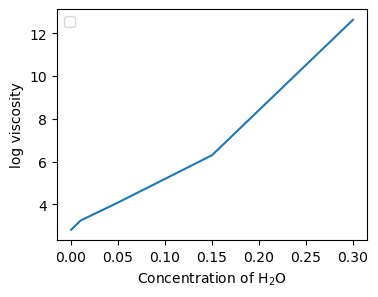

In [10]:
# plotting

fig, ax = plt.subplots(1,1)
fig.set_size_inches(4,3)

ax.plot(cryst_frac, eta, label="Viscosity vs H2O")
    
ax.set_ylabel("log viscosity")
ax.set_xlabel(r'Concentration of Crystals')
plt.legend()
plt.show()

In [9]:
## Einstein Roscoe viscosity computations


***

#### <b><u> TASK 2 QUESTIONS</u> (6 pts) </b>

Based on your exploration of how the viscosity of your chosen magma changes as it rises to the surface and it decompresses, cools, and crystallizes, as well as what you learned in class, answer the following questions.

<ol>
    <li> If you assume that the results from Task 2 above represent the changes in viscosity as your magma rose to the surface before/during eruption, how many orders of magnitude did its bulk viscosity change from the storage region at 4000 meters depth, to the surface? ( 1 pt) </li>
    <li> The dramatic changes in viscosity you observe relate to changes in the rheology of the bulk magma. Crystal-free “magma” has no yield strength. Which rheology relationship will best describe your magma at the starting conditions before crystals form? (1 pt) </li>
    <li> As soon as crystals start to form, magma can develop a yield strength (<a href="https://www.sciencedirect.com/science/article/pii/S0012821X13005335">Chevrel et al., 2013</a>). Let’s assume that your magma develops a yield strength when the crystals reach 15 vol %. What is the corresponding viscosity at this point from your models? What rheology would describe it best? (1 pt) </li>
    <li> How easily will this magma flow, relative to the starting conditions when it had no crystals? What could happen to its ascent rate as it continues to rise and more crystals form? (1 pt) </li>
    <li> Despite this, we know that magmas with 30+ vol % crystals can and do erupt (which means they have not completely frozen and stalled in the conduit). What process (or rheologic behavior) explains this? (2 pt) </li>
    
</ol>
